# BÀI THỰC HÀNH 4: SO SÁNH SỰ TƯƠNG ĐỒNG CỦA ẢNH BẰNG WAVELET HASH

Notebook này **không viết lại thuật toán**: mọi hàm xử lý (`bam_wavelet`, `tinh_khoang_cach_hamming`, `agent_rule`, `khao_sat_cac_wavelet`, `danh_sach_cap_test`) được import từ `Lab4.py`. Notebook chỉ gọi các hàm đó, hiển thị kết quả và lưu hình vào `ket_qua/` để đưa vào report.

Các phần:
1. Băm ảnh bằng Wavelet Hash
2. So sánh từng cặp ảnh bằng khoảng cách Hamming và luật tác tử (ngưỡng 150)
3. Đánh giá trên 12 cặp test: bảng so sánh họ wavelet, ma trận nhầm lẫn, đường ROC
4. Ứng dụng tìm kiếm ảnh (Top 3 ảnh giống nhất)

In [1]:
from pathlib import Path
import os
import cv2
import numpy as np
import pywt
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc, accuracy_score

from Lab4 import bam_wavelet, tinh_khoang_cach_hamming, agent_rule, khao_sat_cac_wavelet, danh_sach_cap_test

DATA_DIR = Path("du_lieu")
OUTPUT_DIR = Path("ket_qua")
OUTPUT_DIR.mkdir(exist_ok=True)

WAVELET = "db4"   # họ wavelet chính
NGUONG = 150      # ngưỡng của luật tác tử

data_test = danh_sach_cap_test(str(DATA_DIR))
print("Số cặp test:", len(data_test))

Số cặp test: 12


## 1. Băm ảnh bằng Wavelet Hash

Các bước trong `bam_wavelet`: đọc ảnh xám → resize 256×256 → `pywt.wavedec2(img, 'db4', level=3)` → lấy dải tần thấp **LL** → so với **trung vị** của LL: lớn hơn thì bit 1, còn lại bit 0.

*Ghi chú:* cell dưới gọi lại `pywt.wavedec2` với đúng tham số như trong `bam_wavelet` **chỉ để hiển thị** dải LL và mã băm dạng ảnh 2D. Mã băm dùng để so sánh vẫn lấy từ `bam_wavelet`.

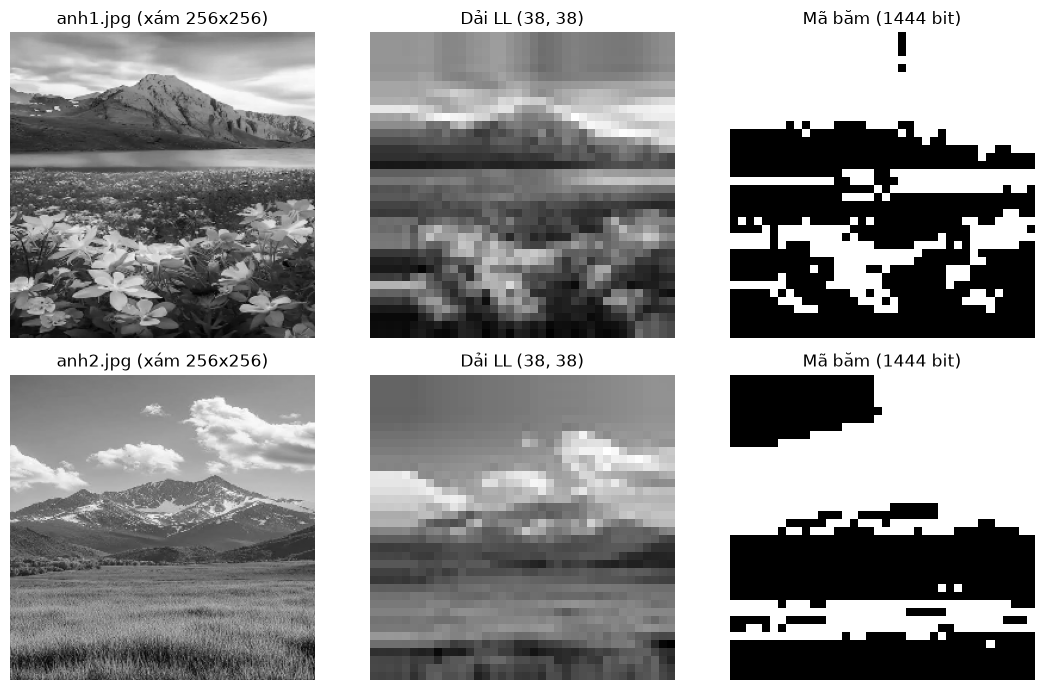

In [2]:
def doc_xam_256(path):
    # Giống bước tiền xử lý trong bam_wavelet: đọc xám + resize 256x256
    return cv2.resize(cv2.imread(str(path), cv2.IMREAD_GRAYSCALE), (256, 256))

anh_mau = ["anh1.jpg", "anh2.jpg"]
fig, axes = plt.subplots(len(anh_mau), 3, figsize=(11, 7))
for r, ten in enumerate(anh_mau):
    img = doc_xam_256(DATA_DIR / ten)
    LL = pywt.wavedec2(img, WAVELET, level=3)[0]
    h = bam_wavelet(str(DATA_DIR / ten), wavelet=WAVELET)
    assert np.array_equal(h, (LL > np.median(LL)).flatten().astype(int))  # khớp với bam_wavelet

    axes[r, 0].imshow(img, cmap="gray"); axes[r, 0].set_title(f"{ten} (xám 256x256)")
    axes[r, 1].imshow(LL, cmap="gray"); axes[r, 1].set_title(f"Dải LL {LL.shape}")
    axes[r, 2].imshow(h.reshape(LL.shape), cmap="gray"); axes[r, 2].set_title(f"Mã băm ({h.size} bit)")
    for ax in axes[r]: ax.axis("off")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "bai1_wavelet_hash.png", dpi=120, bbox_inches="tight")
plt.show()

## 2. So sánh từng cặp ảnh

Với mỗi cặp: tính khoảng cách Hamming giữa 2 mã băm, rồi áp dụng luật tác tử `agent_rule`: khoảng cách ≤ 150 → **1 (Tương đồng)**, ngược lại → **0 (Khác biệt)**.

In [3]:
ket_qua_cap = []
for p1, p2, nhan in data_test:
    kc = tinh_khoang_cach_hamming(bam_wavelet(p1, wavelet=WAVELET), bam_wavelet(p2, wavelet=WAVELET))
    du_doan = agent_rule(kc, NGUONG)
    ket_qua_cap.append((p1, p2, nhan, kc, du_doan))

print(f"{'Ảnh 1':<20} {'Ảnh 2':<20} {'Nhãn':>4} {'Hamming':>8} {'Dự đoán':>8}  Đúng?")
for p1, p2, nhan, kc, dd in ket_qua_cap:
    print(f"{os.path.basename(p1):<20} {os.path.basename(p2):<20} {nhan:>4} {kc:>8} {dd:>8}  {'✓' if nhan == dd else '✗'}")

Ảnh 1                Ảnh 2                Nhãn  Hamming  Dự đoán  Đúng?
anh1.jpg             anh1_challenge.jpg      1       44        1  ✓
anh2.jpg             anh2_challenge.jpg      1       68        1  ✓
anh1.jpg             anh1_mo.jpg             1       24        1  ✓
anh2.jpg             anh2_mo.jpg             1       20        1  ✓
anh1.jpg             anh1_xoay90.jpg         1      712        0  ✗
anh2.jpg             anh2_xoay90.jpg         1      702        0  ✗
anh1.jpg             anh2.jpg                0      574        0  ✓
anh1_challenge.jpg   anh2.jpg                0      580        0  ✓
anh1.jpg             anh2_challenge.jpg      0      542        0  ✓
anh1_mo.jpg          anh2_mo.jpg             0      570        0  ✓
anh1_xoay90.jpg      anh2_xoay90.jpg         0      484        0  ✓
anh1_mo.jpg          anh2_challenge.jpg      0      532        0  ✓


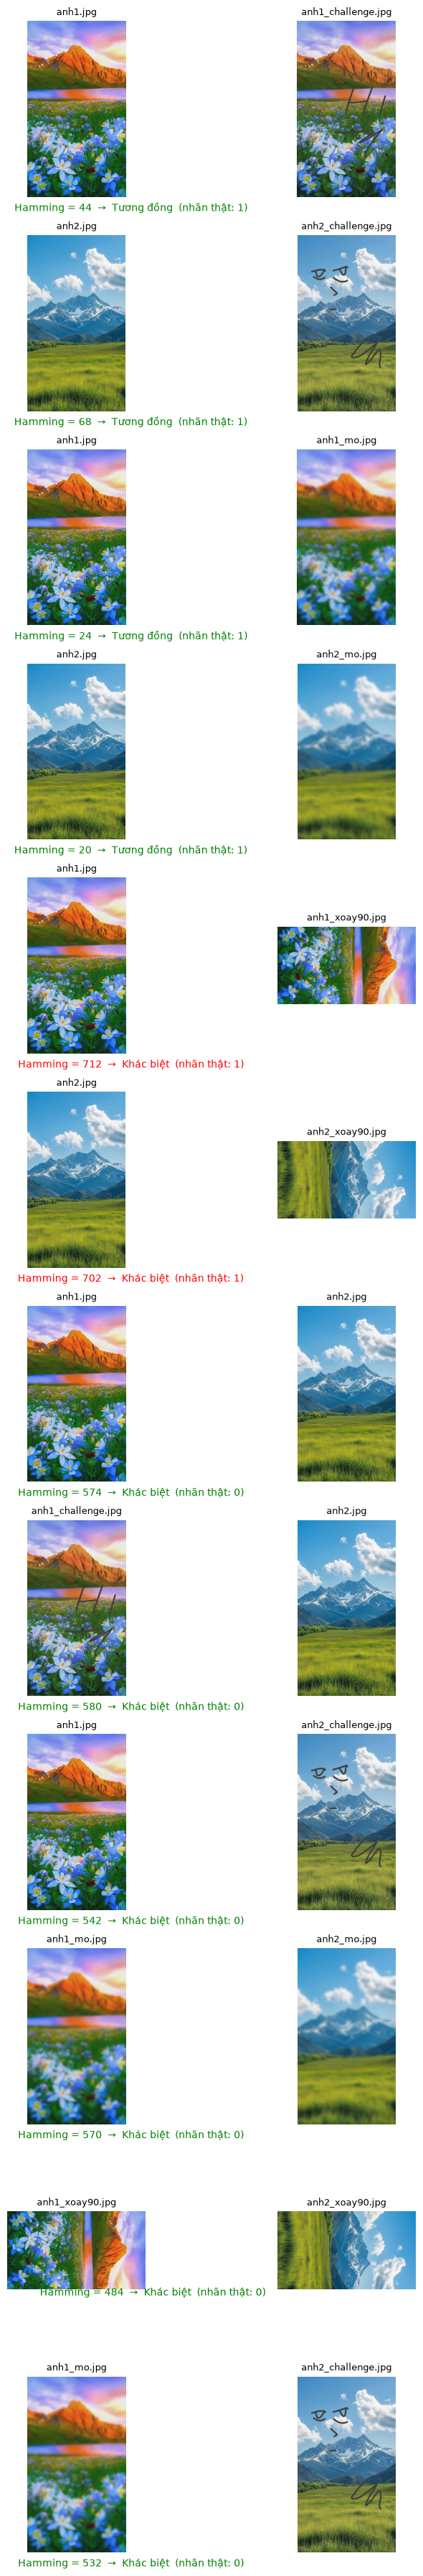

In [4]:
fig, axes = plt.subplots(len(ket_qua_cap), 2, figsize=(6, 3 * len(ket_qua_cap)))
for r, (p1, p2, nhan, kc, dd) in enumerate(ket_qua_cap):
    for c, p in enumerate((p1, p2)):
        axes[r, c].imshow(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB))
        axes[r, c].set_title(os.path.basename(p), fontsize=9)
        axes[r, c].axis("off")
    ket_luan = "Tương đồng" if dd == 1 else "Khác biệt"
    mau = "green" if nhan == dd else "red"
    axes[r, 0].text(1.05, -0.08, f"Hamming = {kc}  →  {ket_luan}  (nhãn thật: {nhan})",
                    transform=axes[r, 0].transAxes, ha="center", fontsize=10, color=mau)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "bai2_so_sanh_cap_anh.png", dpi=100, bbox_inches="tight")
plt.show()

## 3. Đánh giá trên 12 cặp test

### 3.1. So sánh các họ wavelet (haar, db4, sym4, coif1) với ngưỡng 150

In [5]:
khao_sat_cac_wavelet(data_test, nguong=NGUONG)


 BẢNG SO SÁNH HIỆU SUẤT CÁC PHƯƠNG PHÁP WAVELET (BÀI NÂNG CAO 1)
Ho Wavelet      | Do Chinh Xac    | Do Nhay    | Do Dac Hieu 
----------------------------------------------------------------------
haar            |          83.33% |     66.67% |      100.00%
db4             |          83.33% |     66.67% |      100.00%
sym4            |          83.33% |     66.67% |      100.00%
coif1           |          83.33% |     66.67% |      100.00%



### 3.2. Ma trận nhầm lẫn (db4, ngưỡng 150)

Accuracy = 83.33%


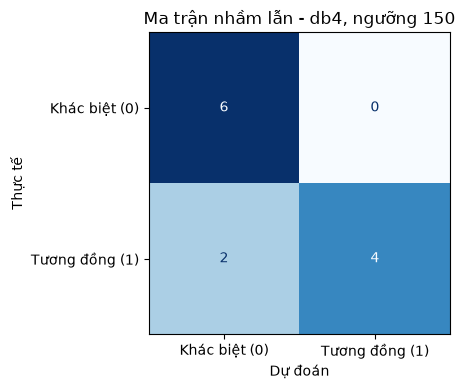

In [6]:
nhan_that = [r[2] for r in ket_qua_cap]
nhan_du_doan = [r[4] for r in ket_qua_cap]
cm = confusion_matrix(nhan_that, nhan_du_doan, labels=[0, 1])
print(f"Accuracy = {accuracy_score(nhan_that, nhan_du_doan) * 100:.2f}%")

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(cm, display_labels=["Khác biệt (0)", "Tương đồng (1)"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Ma trận nhầm lẫn - {WAVELET}, ngưỡng {NGUONG}")
ax.set_xlabel("Dự đoán"); ax.set_ylabel("Thực tế")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "bai3_ma_tran_nham_lan.png", dpi=120, bbox_inches="tight")
plt.show()

### 3.3. Đường ROC

Điểm tương đồng = −(khoảng cách Hamming), giống `Lab4.py`: khoảng cách càng nhỏ thì điểm càng cao.

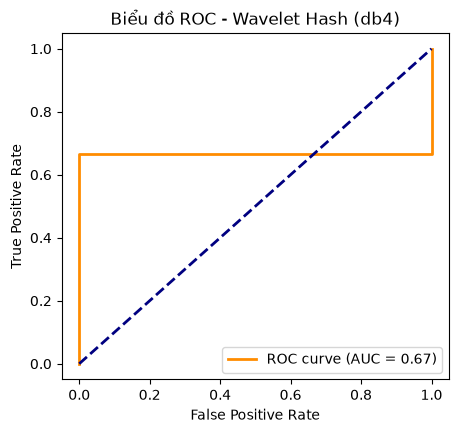

In [7]:
diem = [-r[3] for r in ket_qua_cap]
fpr, tpr, _ = roc_curve(nhan_that, diem)
roc_auc = auc(fpr, tpr)

fig = plt.figure(figsize=(5, 4.5))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title(f"Biểu đồ ROC - Wavelet Hash ({WAVELET})")
plt.legend(loc="lower right")
fig.savefig(OUTPUT_DIR / "bai3_roc_db4.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Ứng dụng tìm kiếm ảnh

Cùng cách làm với `app_tim_kiem.py`: băm ảnh truy vấn, tính Hamming với mọi ảnh còn lại trong `du_lieu/`, sắp xếp tăng dần và lấy Top 3. Ở đây đặt sẵn tên ảnh thay cho `input()` để notebook chạy được từ đầu đến cuối.

 -> anh1_mo.jpg (Khoảng cách Hamming: 24)
 -> anh1_challenge.jpg (Khoảng cách Hamming: 44)
 -> anh2_challenge.jpg (Khoảng cách Hamming: 542)


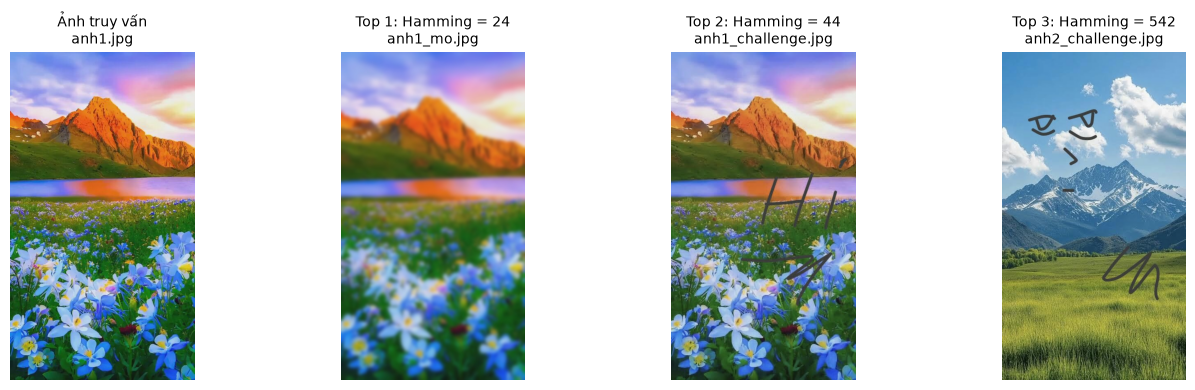

In [8]:
ANH_TRUY_VAN = "anh1.jpg"   # đổi ảnh truy vấn ở đây

h_goc = bam_wavelet(str(DATA_DIR / ANH_TRUY_VAN), wavelet=WAVELET)
xep_hang = sorted(
    (tinh_khoang_cach_hamming(h_goc, bam_wavelet(str(p), wavelet=WAVELET)), p.name)
    for p in sorted(DATA_DIR.glob("*.jpg")) if p.name != ANH_TRUY_VAN
)
top3 = xep_hang[:3]
for kc, ten in top3:
    print(f" -> {ten} (Khoảng cách Hamming: {kc})")

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, (ten, tieu_de) in zip(axes, [(ANH_TRUY_VAN, "Ảnh truy vấn")] + [(t, f"Top {i+1}: Hamming = {k}") for i, (k, t) in enumerate(top3)]):
    ax.imshow(cv2.cvtColor(cv2.imread(str(DATA_DIR / ten)), cv2.COLOR_BGR2RGB))
    ax.set_title(f"{tieu_de}\n{ten}", fontsize=10)
    ax.axis("off")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "bai4_tim_kiem_top3.png", dpi=120, bbox_inches="tight")
plt.show()

## Nhận xét

*(Viết dựa trên kết quả chạy ở trên: các cặp bị dự đoán sai, ảnh hưởng của phép xoay 90°, so sánh các họ wavelet, ý nghĩa AUC.)*